## Lab: Visualization
#### Anna G. Castillo

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

##### Data: 
Please download the data set titled "SPSS_cars_v2.csv" from the course website to use with this lab session. This data set includes 113 car models with information related to their make, sales, performance, size, etc. In addition, the country origin of the car brand is also provided in the "country" column. Sales, resale and price values are in 1,000 units. Engine_s is the engine size, horsepow is the horsepower, mpg is the mileage per gallon and fuel_cap is the fuel capacity in gallon.   

In [3]:
df = pd.read_csv("SPSS_cars_v2.csv")
print(df.shape)
df.head()

(113, 14)


,manufact,model,sales,resale,price,engine_s,horsepow,wheelbas,width,length,curb_wgt,fuel_cap,mpg,country
0,Acura,Integra,16.92,16.360,21.5,1.8,140,101.2,67.3,172.4,2.639,13.2,28.0,Japan
1,Acura,TL,39.38,19.875,28.4,3.2,225,108.1,70.3,192.9,3.517,17.2,25.0,Japan
2,Acura,CL,14.11,18.225,NaN,3.2,225,106.9,70.6,192.0,3.470,17.2,26.0,Japan
3,Acura,RL,8.59,29.725,42.0,3.5,210,114.6,71.4,196.6,3.850,18.0,22.0,Japan
4,Cadillac,DeVille,63.73,22.525,39.9,4.6,275,115.3,74.5,207.2,3.978,18.5,22.0,United States


In [4]:
print(df["country"].value_counts())
print(df.isna().sum())

country
United States    54
Japan            38
Germany          15
Sweden            6
Name: count, dtype: int64
manufact     0
model        0
sales        0
resale      26
price        1
engine_s     0
horsepow     0
wheelbas     0
width        0
length       0
curb_wgt     1
fuel_cap     0
mpg          2
country      0
dtype: int64


#### Question 1: For each country in the data, generate a separate histogram of the mpg attribute and display all the histograms within a single matplotlib Figure object.  
- There should be as many axes (subplots) as the number of unique country values.
- Use 5 bins in the histograms.
- Use titles to match country names to subplots.
- Notice that some of the mpg values are missing. You should remove the observations with missing mpg values from the data when plotting histograms.
- Minimize hard coding as much as possible.
- Provide a screenshot of the Figure as your answer to this question. 

['Japan' 'United States' 'Germany' 'Sweden']


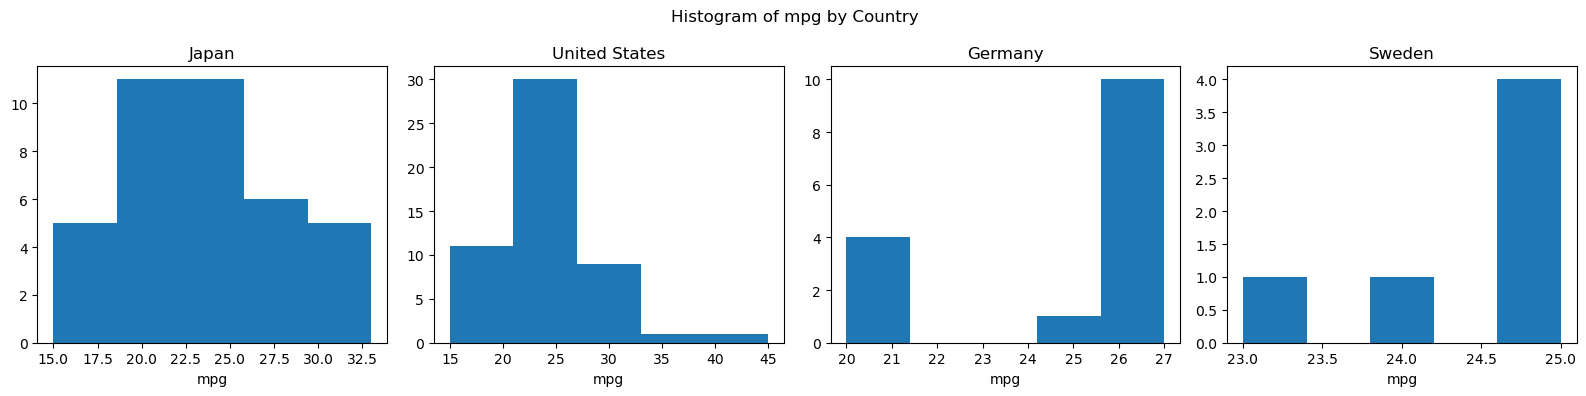

In [5]:
df_mpg = df.dropna(subset=["mpg"])
countries = df_mpg["country"].unique()
print(countries)

fig = plt.figure(figsize=(16, 4))
for i in range(len(countries)):
    ax = fig.add_subplot(1, len(countries), i + 1)
    ax.hist(df_mpg.loc[df_mpg["country"] == countries[i], "mpg"], bins=5)
    ax.set_title(countries[i])
    ax.set_xlabel("mpg")
fig.suptitle("Histogram of mpg by Country")
fig.tight_layout()
plt.show()

#### Question 2: Use side-by-side box plots to compare the countries in terms of their distribution of the following four attributes: price, sales, resale, horsepow. Display the four subplots within the same Figure object.
- There should be as many axes (subplots) as the number of attributes of interest.
- Use titles to match attribute names to subplots.
- Make sure that there is enough padding between individual box plots for the country names not to overlap with each other.
- Provide a screenshot of the Figure as your answer to this question. 

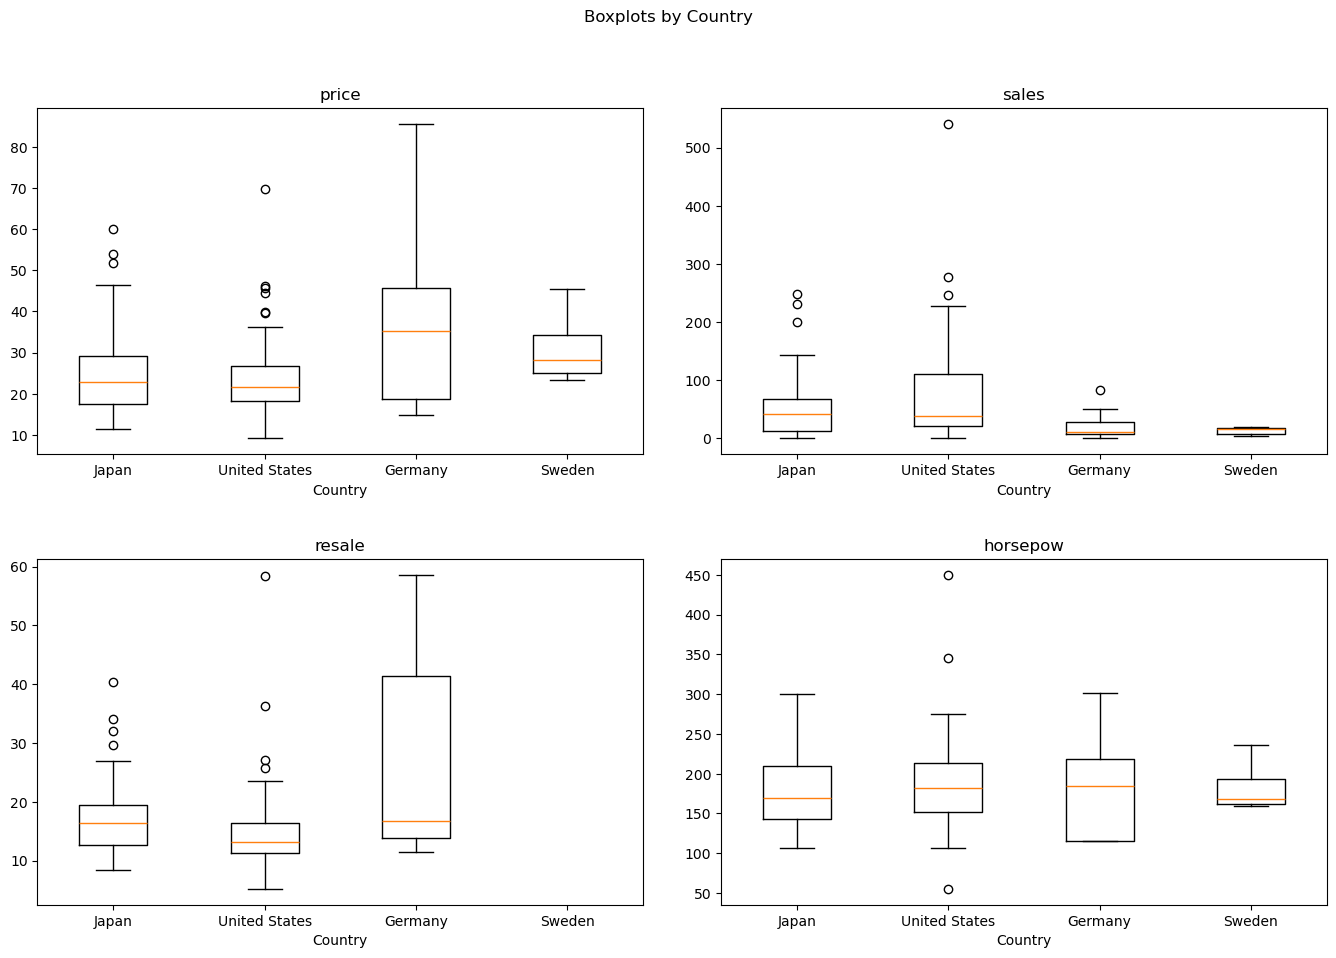

In [6]:
attributes = ["price", "sales", "resale", "horsepow"]
countries = df["country"].unique()

fig = plt.figure(figsize=(14, 10))
for i in range(len(attributes)):
    ax = fig.add_subplot(2, 2, i + 1)
    attList = []
    for country in countries:
        attList.append(df.loc[df["country"] == country, attributes[i]].dropna())
    ax.boxplot(attList)
    ax.set_xticklabels(countries)
    ax.set_title(attributes[i])
    ax.set_xlabel("Country")
fig.suptitle("Boxplots by Country")
fig.tight_layout(pad=3)
3plt.show()

#### Question 3: Provide a “width” vs. “length” scatter plot for each country in the same Figure object using different subplots. Provide a screenshot of the Figure as your answer to this question. 

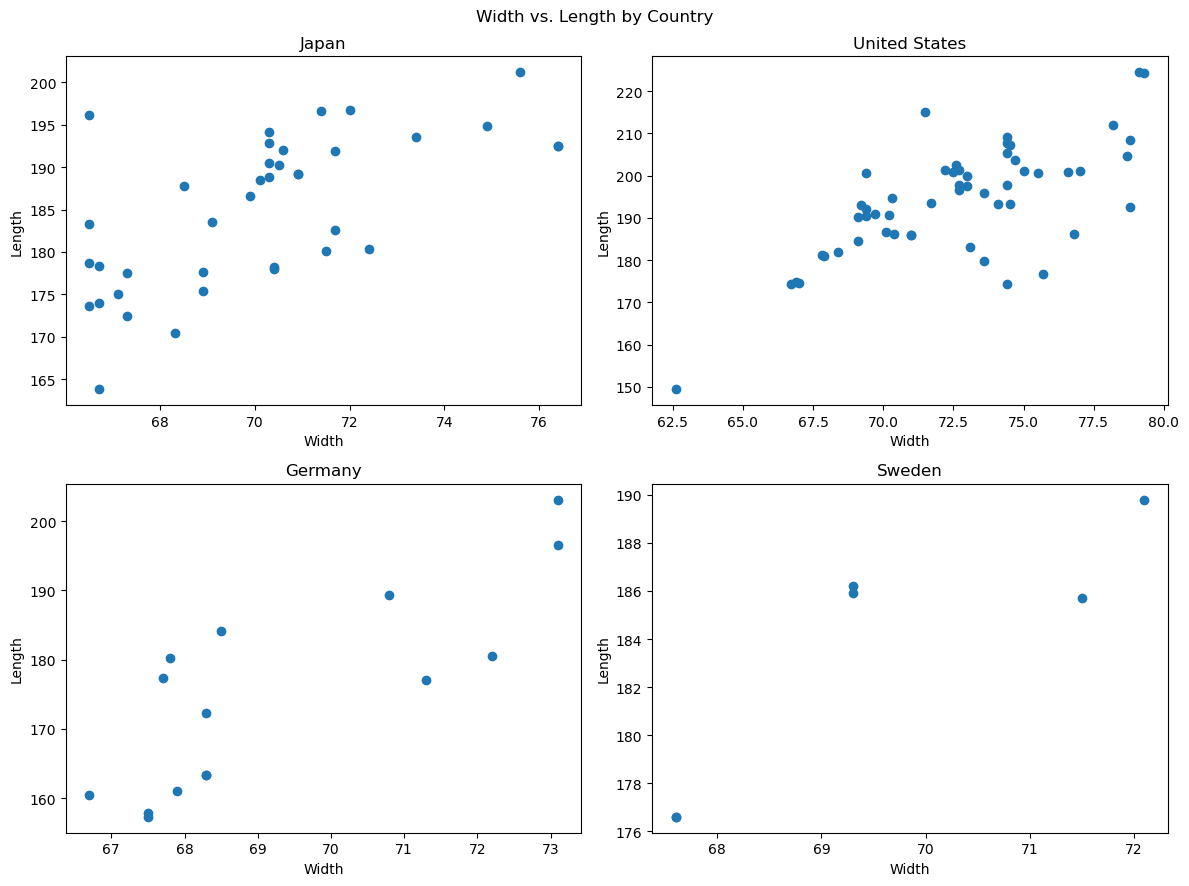

In [7]:
countries = df["country"].unique()

fig = plt.figure(figsize=(12, 9))
for i in range(len(countries)):
    ax = fig.add_subplot(2, 2, i + 1)
    country_df = df[df["country"] == countries[i]]
    ax.scatter(country_df["width"], country_df["length"])
    ax.set_title(countries[i])
    ax.set_xlabel("Width")
    ax.set_ylabel("Length")
fig.suptitle("Width vs. Length by Country")
fig.tight_layout()
plt.show()

#### Question 4: Provide a bar chart of the number of different car models manufactured by the “United States” car manufacturers. Each bar should correspond to a single manufacturer and the length of the bar should indicate the number of unique car models manufactured. 

manufact
Cadillac       5
Chevrolet      9
Chrysler       6
Dodge         11
Ford          11
Oldsmobile     6
Pontiac        6
Name: model, dtype: int64


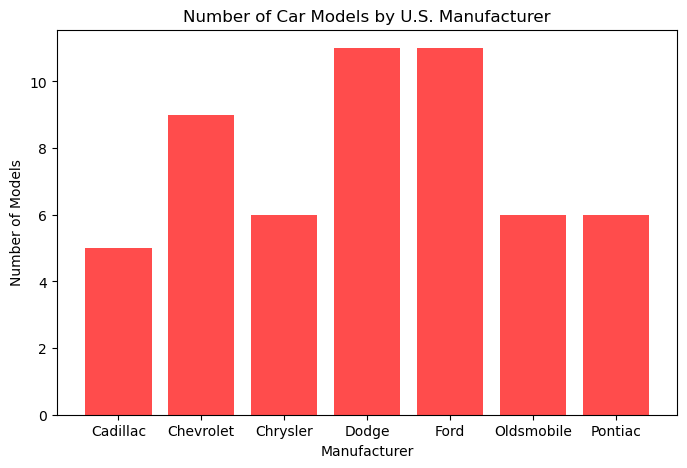

In [8]:
us = df[df["country"] == "United States"]
modelsByManu = us.groupby("manufact")["model"].nunique()
print(modelsByManu)

fig = plt.figure(figsize=(8, 5))
ax1 = fig.add_subplot(1, 1, 1)
ax1.bar(range(modelsByManu.shape[0]), modelsByManu.values, color="red", alpha=0.7, tick_label=modelsByManu.index)
ax1.set_title("Number of Car Models by U.S. Manufacturer")
ax1.set_xlabel("Manufacturer")
ax1.set_ylabel("Number of Models")
plt.show()

#### Question 5: Create a bar chart similar to Q4 – however this time include all the countries. This should be a single bar chart (a single figure and subplot). Differentiate the countries by color and make sure the manufacturer’s name is visible under each bar. The expected output should look like the figure below. 

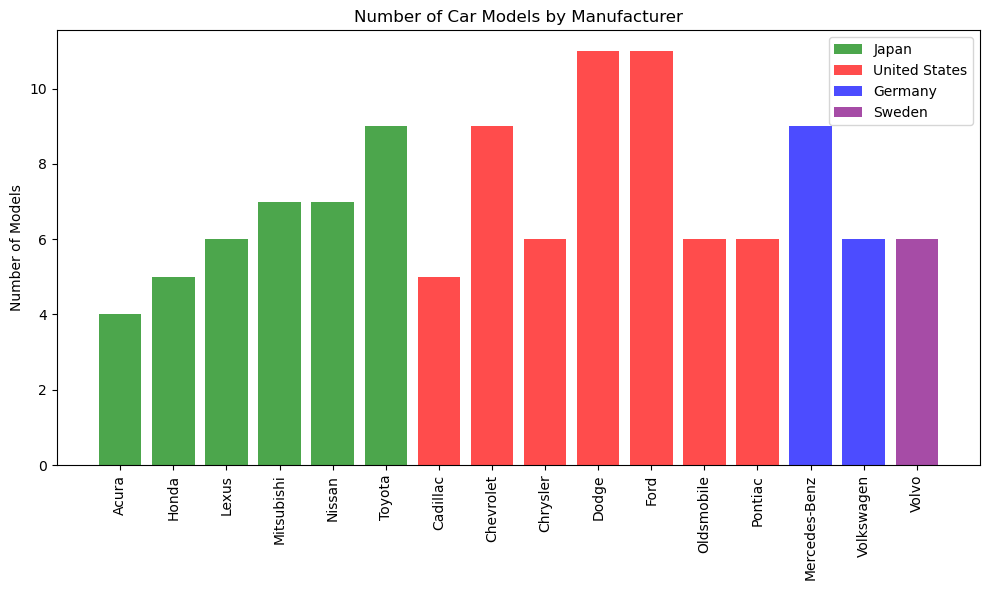

In [9]:
countries = df["country"].unique()
colors = ["green", "red", "blue", "purple"]

fig = plt.figure(figsize=(10, 6))
ax1 = fig.add_subplot(1, 1, 1)
start = 0
positions = []
names = []
for i in range(len(countries)):
    country_df = df[df["country"] == countries[i]]
    modelsByManu = country_df.groupby("manufact")["model"].nunique()
    x = range(start, start + modelsByManu.shape[0])
    ax1.bar(x, modelsByManu.values, color=colors[i], alpha=0.7, label=countries[i])
    positions.extend(x)
    names.extend(modelsByManu.index)
    start = start + modelsByManu.shape[0]
ax1.set_xticks(positions)
ax1.set_xticklabels(names, rotation=90)
ax1.set_title("Number of Car Models by Manufacturer")
ax1.set_ylabel("Number of Models")
ax1.legend()
fig.tight_layout()
plt.show()

#### Question 6: The “What would you like to show” slide in the lecture slide deck provides a good summary of commonly used visualization plots. Choose one from that figure and create this plot using one or more attributes from the car data set. The selection is up to you; however, it should be different than the ones asked in earlier questions. You can use coloring schemes, titles, labels, legends, etc., to improve the aesthetics of the chart. 

country
United States    4297.15
Japan            2099.28
Germany           326.33
Sweden             75.75
Name: sales, dtype: float64


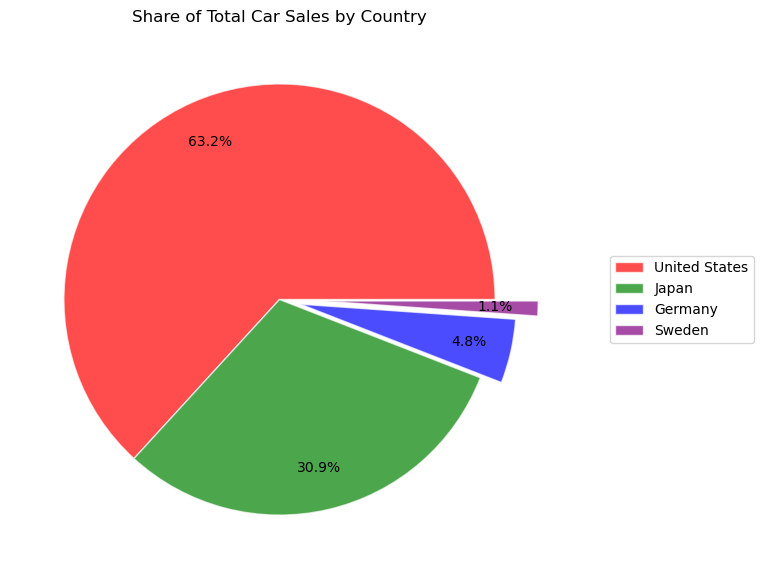

In [10]:
salesByCountry = df.groupby("country")["sales"].sum().sort_values(ascending=False)
print(salesByCountry)

fig = plt.figure(figsize=(9, 7))
ax1 = fig.add_subplot(1, 1, 1)
ax1.pie(salesByCountry.values, autopct="%1.1f%%", explode=[0, 0, 0.1, 0.2],
        colors=["red", "green", "blue", "purple"], startangle=0, pctdistance=0.8,
        wedgeprops={"alpha": 0.7, "edgecolor": "white"})
ax1.legend(salesByCountry.index, loc="center left", bbox_to_anchor=(1.1, 0.5))
ax1.set_title("Share of Total Car Sales by Country")
plt.show()